In [1]:
import os
import cv2
import numpy as np
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns


In [37]:
image_path = "/Users/enve/Documents/Uni/Computer Vision/Percobaan 2/train"
test_image = "thumb-orange-640x480-orange (1).jpg"

In [45]:
def extract_features(image_path, size=(128, 128)):
    img = cv2.imread(image_path)
    if img is None: return None

    img_resized = cv2.resize(img, size)
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    h, w = blurred.shape[:2]
    margin = int(min(h, w) * 0.085)
    rect = (margin, margin, w - margin*2, h - margin*2)
    mask     = np.zeros(blurred.shape[:2], np.uint8)
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(img_resized, mask, rect, bgd_model, fgd_model,
                iterCount=20, mode=cv2.GC_INIT_WITH_RECT)

    mask2 = np.where((mask == 2) | (mask == 0), 0, 255).astype('uint8')

    # plt.imshow(mask2, cmap="gray")

    # Shape features
    contours, _ = cv2.findContours(mask2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    aspect_ratio, extent = 0, 0
    if contours:
        c = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(c)
        aspect_ratio = float(w) / h if h != 0 else 0
        area = cv2.contourArea(c)
        rect_area = w * h
        extent = float(area) / rect_area if rect_area != 0 else 0

    fp = mask2 > 0

    # HSV color features
    hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
    h_ch, s_ch, v_ch = cv2.split(hsv)
    hsv_feats = [
        np.mean(h_ch[fp]) if fp.any() else 0,
        np.mean(s_ch[fp]) if fp.any() else 0,
        np.mean(v_ch[fp]) if fp.any() else 0,
        np.std(h_ch[fp])  if fp.any() else 0,
        np.std(s_ch[fp])  if fp.any() else 0,
        np.std(v_ch[fp])  if fp.any() else 0,
    ]

    # LAB color features (perceptual color - helps Ripe vs Unripe separation)
    lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    lab_feats = [
        np.mean(l_ch[fp]) if fp.any() else 0,
        np.mean(a_ch[fp]) if fp.any() else 0,  # green-red axis
        np.mean(b_ch[fp]) if fp.any() else 0,  # blue-yellow axis
        np.std(a_ch[fp])  if fp.any() else 0,
        np.std(b_ch[fp])  if fp.any() else 0,
    ]

    # Hue histogram (18 bins) - captures color distribution, not just mean/std
    h_hist = cv2.calcHist([h_ch], [0], mask, [18], [0, 180])
    h_hist = cv2.normalize(h_hist, h_hist).flatten().tolist()

    # GLCM texture with more distances and angles
    # Do this — crop to bounding box of the mask, 
    # then only pass actual fruit pixels
    x, y, bw, bh = cv2.boundingRect(mask2)
    gray_crop = gray[y:y+bh, x:x+bw]
    mask_crop = mask2[y:y+bh, x:x+bw]

    masked_gray_raw = np.where(mask_crop > 0, gray_crop, 0).astype(np.uint8)
    inv_mask_crop   = cv2.bitwise_not(mask_crop)
    if np.count_nonzero(inv_mask_crop) > 0:
        masked_gray = cv2.inpaint(masked_gray_raw, inv_mask_crop,
                                inpaintRadius=1, flags=cv2.INPAINT_TELEA)
        if masked_gray is None:  # inpaint can still return None on edge cases
            masked_gray = masked_gray_raw
    else:
        # Mask fills entire crop — no background to inpaint
        masked_gray = masked_gray_raw

    # Quantize
    masked_gray_q = (masked_gray // 8).astype(np.uint8)
    valid_pixels = masked_gray_q[masked_gray_q > 0]
    if valid_pixels.size < 100:  # threshold: at least 100 valid pixels
        # Fallback: use the full (unmasked) grayscale image
        gray_q = (cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) // 8).astype(np.uint8)
        glcm_input = gray_q
    else:
        glcm_input = masked_gray_q

    glcm = graycomatrix(glcm_input, distances=[1, 3, 5],
                        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=True)
    glcm_feats = [
        graycoprops(glcm, 'contrast').mean(),
        graycoprops(glcm, 'correlation').mean(),
        graycoprops(glcm, 'energy').mean(),
        graycoprops(glcm, 'homogeneity').mean(),
        graycoprops(glcm, 'dissimilarity').mean(),
        graycoprops(glcm, 'ASM').mean(),
    ]

    # LBP texture (10 bins) - captures surface patterns like spots/wrinkles
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_pixels = lbp[fp] if fp.any() else lbp.ravel()
    lbp_hist, _ = np.histogram(lbp_pixels, bins=10, range=(0, 10), density=True)

    return hsv_feats + lab_feats + h_hist + glcm_feats + lbp_hist.tolist() + [aspect_ratio, extent]


In [41]:
from tqdm import tqdm

ALLOWED_FRUITS = {'RipeBanana', 'RottenBanana', 'UnripeBanana',
                  'RipeStrawberry', 'RottenStrawberry', 'UnripeStrawberry',
                  'RipeOrange', 'RottenOrange', 'UnripeOrange'}

def load_dataset(path):
    features, labels = [], []
    image_paths = []
    for root, dirs, files in os.walk(path):
        folder_name = os.path.basename(root)
        if folder_name not in ALLOWED_FRUITS:
            continue                          # ← skip non-target fruits
        for file in files:
            if file.lower().endswith(('.jpg', '.png', '.jpeg')):
                image_paths.append(os.path.join(root, file))

    for img_path in tqdm(image_paths, desc="Extracting"):
        feat = extract_features(img_path)
        if feat is not None:
            features.append(feat)
            labels.append(os.path.basename(os.path.dirname(img_path)))
    return np.array(features), np.array(labels)

In [46]:
dataset_base_dir = "/Users/enve/Documents/Uni/Computer Vision/Percobaan 2/train"

if not os.path.exists(dataset_base_dir):
    raise ValueError(f"Path direktori tidak ditemukan: {dataset_base_dir}.")

print("Extracting features from the entire dataset...")
X_all, y_all = load_dataset(dataset_base_dir)
print(f"Feature vector size: {X_all.shape[1]} features per image")

print("\nSplitting dataset into 70% Train and 30% Test...")
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)
print(f"Total data   : {len(X_all)}")
print(f"Train set    : {len(X_train)}")
print(f"Test set     : {len(X_test)}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ── Random Forest (fast, strong baseline, no scaling needed) ──────────────────
print("\nTraining Random Forest...")
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test))
print(f"Random Forest Accuracy: {rf_acc*100:.2f}%")

# ── SVM Grid Search (expanded params, parallelized) ───────────────────────────
print("\nStarting Grid Search for SVM...")
param_grid = {
    'C':      [0.1, 1, 10],
    'gamma':  ['scale', 0.001],
    'kernel': ['rbf'],
}
grid = GridSearchCV(
    SVC(decision_function_shape='ovr', probability=True),  # ovr + probability
    param_grid, cv=5, refit=True, verbose=2, n_jobs=-1
)
grid.fit(X_train_scaled, y_train)
print(f"\nBest SVM Parameters: {grid.best_params_}")

svm_acc = accuracy_score(y_test, grid.predict(X_test_scaled))
print(f"\nRandom Forest Accuracy : {rf_acc*100:.2f}%")
print(f"SVM Accuracy           : {svm_acc*100:.2f}%")
best_model_name = 'SVM' if svm_acc >= rf_acc else 'Random Forest'
print(f"Best model             : {best_model_name}")


Extracting features from the entire dataset...


Extracting: 100%|██████████| 7302/7302 [09:31<00:00, 12.78it/s]


Feature vector size: 47 features per image

Splitting dataset into 70% Train and 30% Test...
Total data   : 7302
Train set    : 5111
Test set     : 2191

Training Random Forest...
Random Forest Accuracy: 89.96%

Starting Grid Search for SVM...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   5.0s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   5.0s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   5.1s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   5.2s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   5.4s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   8.0s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   8.1s
[CV] END .....................C=0.1, gamma=0.001, kernel=rbf; total time=   8.1s
[CV] END .....................C=0.1, gamma=0.001

In [47]:
print("Evaluating Best Model Performance...")

if svm_acc >= rf_acc:
    y_pred = grid.predict(X_test_scaled)
    print("Using: SVM")
else:
    y_pred = rf.predict(X_test)
    print("Using: Random Forest")

print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Evaluating Best Model Performance...
Using: Random Forest
Accuracy: 89.96%

Classification Report:
                  precision    recall  f1-score   support

      RipeBanana       0.91      0.98      0.95       240
      RipeOrange       0.87      0.91      0.89       241
  RipeStrawberry       0.95      0.90      0.93       270
    RottenBanana       0.94      0.95      0.95       240
    RottenOrange       0.96      0.93      0.94       240
RottenStrawberry       0.86      0.90      0.88       240
    UnripeBanana       0.89      0.81      0.85       240
    UnripeOrange       0.85      0.87      0.86       240
UnripeStrawberry       0.86      0.83      0.85       240

        accuracy                           0.90      2191
       macro avg       0.90      0.90      0.90      2191
    weighted avg       0.90      0.90      0.90      2191



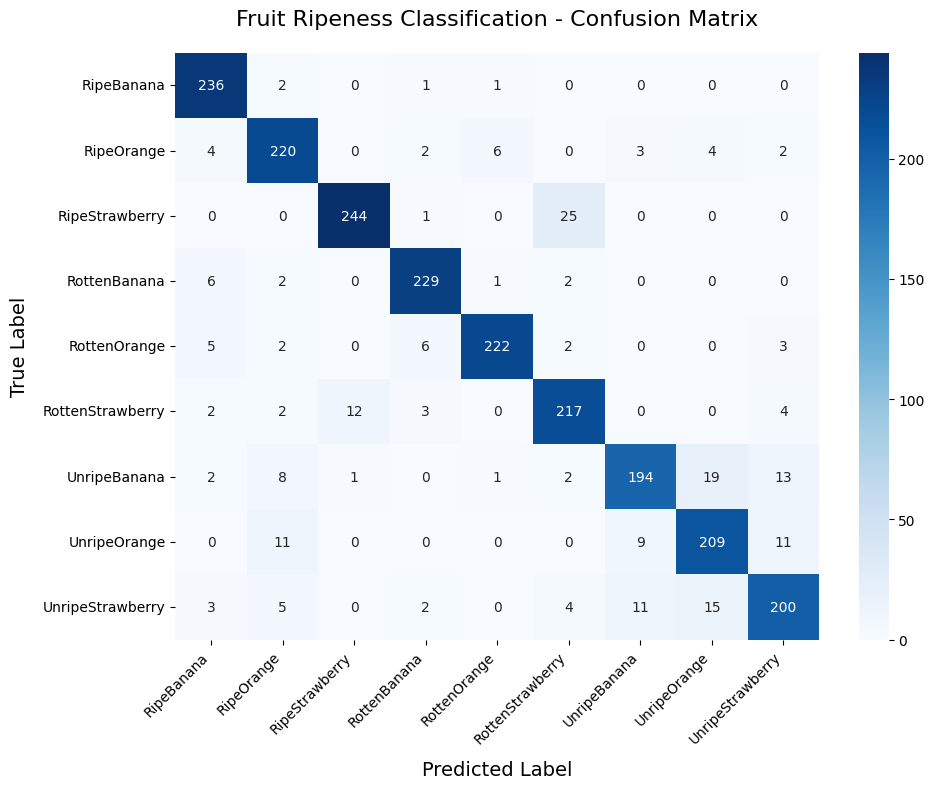

In [48]:
cm = confusion_matrix(y_test, y_pred)

class_names = np.unique(y_test)

plt.figure(figsize=(10, 8))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)

plt.title('Fruit Ripeness Classification - Confusion Matrix', fontsize=16, pad=20)
plt.xlabel('Predicted Label', fontsize=14, labelpad=10)
plt.ylabel('True Label', fontsize=14, labelpad=10)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [49]:
import joblib

joblib.dump(grid.best_estimator_, 'fruit_svm_model.pkl')
joblib.dump(rf,                   'fruit_rf_model.pkl')
joblib.dump(scaler,               'fruit_scaler.pkl')

print("Saved: fruit_svm_model.pkl, fruit_rf_model.pkl, fruit_scaler.pkl")


Saved: fruit_svm_model.pkl, fruit_rf_model.pkl, fruit_scaler.pkl
